<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="VGI logo" width="180"></a>

# Two team rows, one game

Can the shooting counts explain the final score, and does the higher field-goal percentage identify the winner? We pair team game-log rows, reconcile points from made shots, then narrow the comparison to close games.

**Default: a recorded, trimmed real NBA Stats response from this repository’s tests.** It contains four team rows for two games on **2025-10-21** in the **2025–26 regular season**. It is not a complete season. The original capture timestamp was not recorded; the fixture and its SHA-256 provenance are bundled unchanged. Live mode requests the public season endpoint and applies the same historical game-date filter without replay fallback.

## Choose the margin

`MAX_MARGIN` is an inclusive final-score margin in points, an integer from **0 to 50**, default **10**. It selects whole paired games, keeping both teams. `DATA_MODE` is `"replay"` or `"live"`; replay supports only the fixed NBA team-season request shown below. Game dates are NBA schedule dates, not UTC timestamps. Restart and run all after changing a parameter.

In [1]:
DATA_MODE = "replay"
MAX_MARGIN = 10  # include games decided by at most this many points

In [2]:
from datetime import UTC, datetime

import haybarn
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from notebook_support import finish, theme
from recorded_api import configure

assert type(MAX_MARGIN) is int and 0 <= MAX_MARGIN <= 50
replay = configure(DATA_MODE)
run_at = datetime.now(UTC).isoformat(timespec="seconds")
connection = haybarn.connect()
theme()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.feedback = False
%sql connection

Tip: You may define configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-nba/notebooks/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /Users/rusty/Development/notebook-rollout/full-rollout/checkouts/vgi-nba/notebooks/pyproject.toml.

## Retrieve once, then work locally

The literal Git launch is independent of this worker checkout. The replay helper uses the worker’s supported endpoint override and serves only the exact recorded request; SQL still calls the real worker through VGI. Live mode clears those overrides. Materializing the API call avoids repeating a network request while capturing or plotting its result. The season argument is its starting year, **2025**.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'nba' (TYPE vgi, LOCATION 'uvx --python 3.13 --with vgi-python==0.51.0 --with vgi-rpc==0.53.1 --from git+https://github.com/Query-farm/vgi-nba@5d7bb8011fb035530deda5146446ce29313278bd vgi-nba');
CREATE TABLE season_rows AS
SELECT * FROM nba.nba.league_game_log(season := 2025, season_type := 'Regular Season', player_or_team := 'T');
CREATE TABLE day_rows AS
SELECT * FROM season_rows WHERE game_date=DATE '2025-10-21';

,Count


In [4]:
%%sql coverage <<
SELECT (SELECT count(*) FROM season_rows) AS retrieved_team_rows,
 count(*) AS day_team_rows,count(DISTINCT game_id) AS day_games,
 min(game_date) AS first_selected_date,max(game_date) AS last_selected_date FROM day_rows;

In [5]:
display(coverage)
assert int(coverage.day_team_rows.iloc[0]) > 0, "No team rows for the selected historical date"
label = "recorded subset" if DATA_MODE == "replay" else "live response"
display(
    Markdown(
        f"The **{label}** returned **{int(coverage.retrieved_team_rows.iloc[0]):,} team rows** "
        f"the date filter retains **{int(coverage.day_team_rows.iloc[0])} rows** "
        f"covering **{int(coverage.day_games.iloc[0])} games**. "
        f"Run clock: **{run_at}** (UTC), not the fixture capture time. A row describes one team in one game."
    )
)

,retrieved_team_rows,day_team_rows,day_games,first_selected_date,last_selected_date
0,4,4,2,2025-10-21,2025-10-21


The **recorded subset** returned **4 team rows** the date filter retains **4 rows** covering **2 games**. Run clock: **2026-11-14T08:15:01+00:00** (UTC), not the fixture capture time. A row describes one team in one game.

## Pair opponents before filtering

Join the winner and loser on the text game ID. A complete final game should have two distinct team rows, one win and one loss, and opposite point differentials. We retain those checks below rather than assuming a join automatically produces a valid game. The margin filter is applied after pairing, so it cannot discard only one opponent.

In [6]:
%%sql
CREATE TABLE games AS
SELECT w.game_id,w.game_date,w.team_abbreviation AS winner,l.team_abbreviation AS loser,
 w.points AS winner_points,l.points AS loser_points,w.points-l.points AS margin
FROM day_rows w JOIN day_rows l USING(game_id)
WHERE w.win_loss='W' AND l.win_loss='L';
CREATE TABLE selected_games AS SELECT * FROM games WHERE margin<={{MAX_MARGIN}};
CREATE TABLE scoring AS
SELECT d.game_id,d.team_abbreviation,d.opponent_abbreviation,d.win_loss,g.margin,
 d.points,d.field_goals_made,d.field_goals_attempted,d.three_pointers_made,
 d.three_pointers_attempted,d.free_throws_made,d.free_throws_attempted,
 2*(d.field_goals_made-d.three_pointers_made) AS two_point_points,
 3*d.three_pointers_made AS three_point_points,d.free_throws_made AS free_throw_points,
 100.0*d.field_goals_made/nullif(d.field_goals_attempted,0) AS fg_percent,
 100.0*(d.field_goals_made+0.5*d.three_pointers_made)/nullif(d.field_goals_attempted,0) AS effective_fg_percent
FROM day_rows d JOIN selected_games g USING(game_id);

,Count


In [7]:
%%sql paired <<
SELECT *,margin<={{MAX_MARGIN}} AS selected FROM games ORDER BY game_id;

In [8]:
display(paired)

,game_id,game_date,winner,loser,winner_points,loser_points,margin,selected
0,0022500001,2025-10-21,OKC,HOU,125,124,1,True
1,0022500002,2025-10-21,GSW,LAL,119,109,10,True


## Reconcile points from made shots

Field goals include both two- and three-point makes. Therefore **points = 2 × (field goals made − three-pointers made) + 3 × three-pointers made + free throws made**. Counting all field goals as two points and then adding all three-point points would double-count their first two points. The chart displays each team’s three mutually exclusive scoring components.

In [9]:
%%sql teams <<
SELECT * FROM scoring ORDER BY game_id,CASE win_loss WHEN 'W' THEN 0 ELSE 1 END;

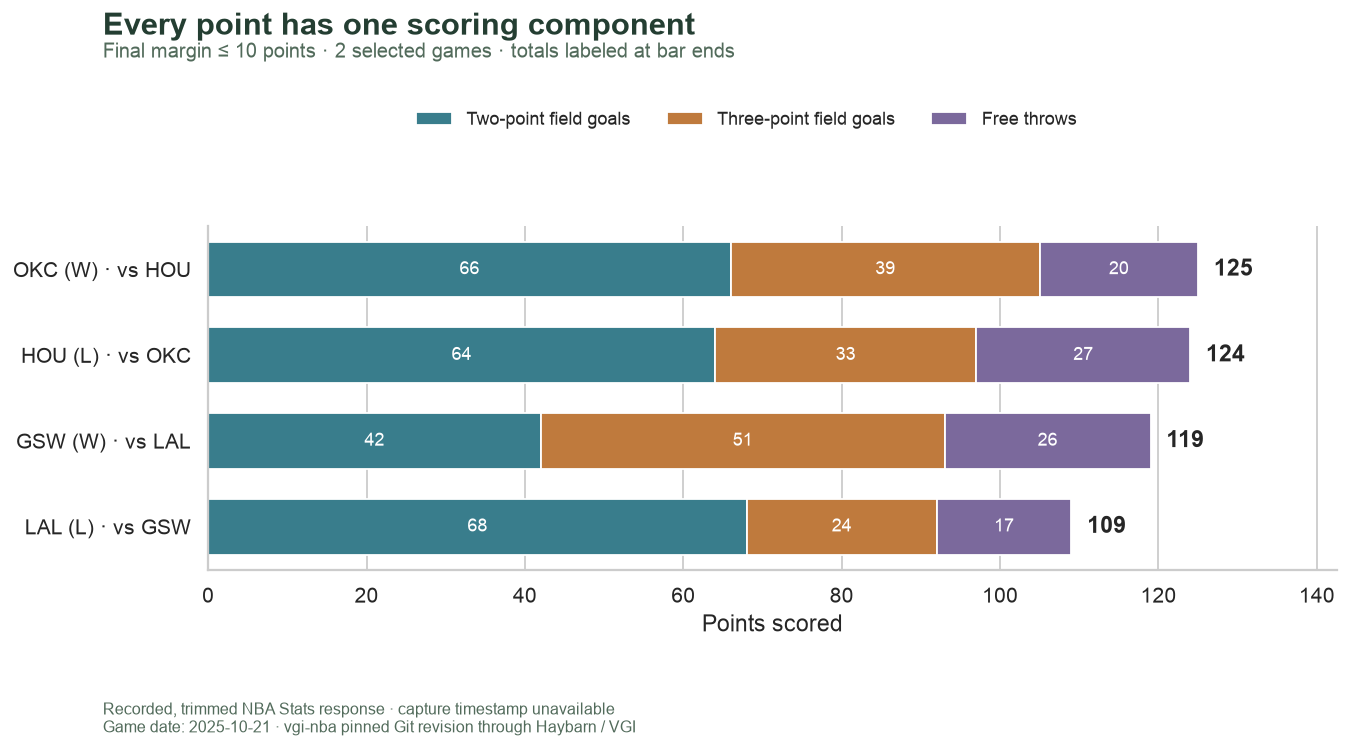

In [10]:
fig, ax = plt.subplots(figsize=(11, 5.8))
labels = [f"{r.team_abbreviation} ({r.win_loss}) · vs {r.opponent_abbreviation}" for r in teams.itertuples()]
bottom = [0] * len(teams)
for column, color, label in [
    ("two_point_points", "#397d8c", "Two-point field goals"),
    ("three_point_points", "#bf7a3d", "Three-point field goals"),
    ("free_throw_points", "#7b699c", "Free throws"),
]:
    bars = ax.barh(range(len(teams)), teams[column], left=bottom, color=color, label=label, height=0.65)
    ax.bar_label(
        bars, labels=[str(int(v)) if v else "" for v in teams[column]], label_type="center", color="white", fontsize=10
    )
    bottom = [a + b for a, b in zip(bottom, teams[column], strict=True)]
for i, total in enumerate(teams.points):
    ax.text(total + 2, i, f"{int(total)}", va="center", fontweight="bold")
ax.set_yticks(range(len(teams)), labels)
ax.invert_yaxis()
ax.set_xlabel("Points scored")
ax.set_ylabel("")
ax.set_xlim(0, max([float(v) for v in teams.points] + [1]) * 1.14)
ax.grid(axis="y", visible=False)
if teams.empty:
    ax.text(0.5, 0.5, "No games satisfy this margin", ha="center", transform=ax.transAxes)
fig.legend(
    *ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.55, 0.87), ncol=3, frameon=False, fontsize=10
)
finish(
    fig,
    f"scoring-margin-{MAX_MARGIN}",
    "Every point has one scoring component",
    f"Final margin ≤ {MAX_MARGIN} points · {len(teams) // 2} selected game{'s' if len(teams) != 2 else ''} "
    "· totals labeled at bar ends",
    DATA_MODE,
)

## Separate shot value from shooting percentage

Ordinary **FG% = FGM / FGA** gives every made field goal equal weight. **Effective FG% = (FGM + 0.5 × 3PM) / FGA** accounts for the extra point on a three-pointer. Both use field-goal attempts as the denominator; effective FG% excludes free throws and is not a probability or a complete measure of performance. A zero attempt count remains unavailable rather than becoming zero.

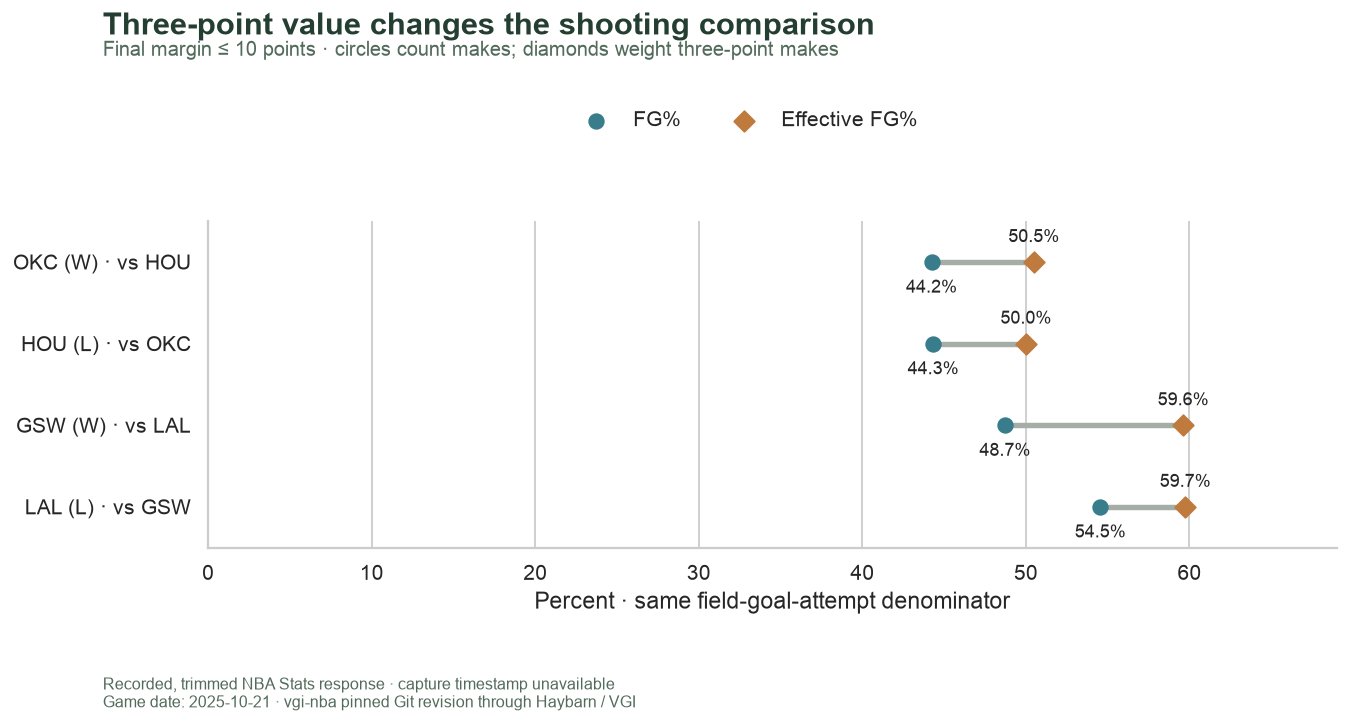

In [11]:
fig, ax = plt.subplots(figsize=(11, 5.6))
for i, row in enumerate(teams.itertuples()):
    if row.fg_percent == row.fg_percent and row.effective_fg_percent == row.effective_fg_percent:
        ax.plot([row.fg_percent, row.effective_fg_percent], [i, i], color="#a4aea6", lw=3, zorder=1)
        ax.scatter(row.fg_percent, i, color="#397d8c", s=65, zorder=2, marker="o")
        ax.scatter(row.effective_fg_percent, i, color="#bf7a3d", s=65, zorder=2, marker="D")
        ax.annotate(
            f"{row.fg_percent:.1f}%",
            (row.fg_percent, i),
            xytext=(0, -17),
            textcoords="offset points",
            ha="center",
            fontsize=10,
        )
        ax.annotate(
            f"{row.effective_fg_percent:.1f}%",
            (row.effective_fg_percent, i),
            xytext=(0, 11),
            textcoords="offset points",
            ha="center",
            fontsize=10,
        )
ax.scatter([], [], color="#397d8c", s=65, label="FG%", marker="o")
ax.scatter([], [], color="#bf7a3d", s=65, label="Effective FG%", marker="D")
ax.set_yticks(range(len(teams)), labels)
ax.set_ylim(len(teams) - 0.5, -0.5)
ax.set_xlabel("Percent · same field-goal-attempt denominator")
ax.set_xlim(0, max([float(v) for v in teams.effective_fg_percent.dropna()] + [60]) * 1.15)
ax.grid(axis="y", visible=False)
if teams.empty:
    ax.text(0.5, 0.5, "No games satisfy this margin", ha="center", transform=ax.transAxes)
fig.legend(*ax.get_legend_handles_labels(), loc="upper center", bbox_to_anchor=(0.55, 0.87), ncol=2, frameon=False)
finish(
    fig,
    f"efficiency-margin-{MAX_MARGIN}",
    "Three-point value changes the shooting comparison",
    f"Final margin ≤ {MAX_MARGIN} points · circles count makes; diamonds weight three-point makes",
    DATA_MODE,
)

In [12]:
%%sql comparisons <<
SELECT g.game_id,g.winner,g.loser,g.margin,w.fg_percent AS winner_fg,l.fg_percent AS loser_fg,
 w.effective_fg_percent AS winner_efg,l.effective_fg_percent AS loser_efg,
 w.two_point_points-l.two_point_points AS two_point_advantage,
 w.three_point_points-l.three_point_points AS three_point_advantage,
 w.free_throw_points-l.free_throw_points AS free_throw_advantage
FROM selected_games g JOIN scoring w ON g.game_id=w.game_id AND w.win_loss='W'
JOIN scoring l ON g.game_id=l.game_id AND l.win_loss='L' ORDER BY g.game_id;

In [13]:
display(comparisons)
paragraphs = []
for row in comparisons.itertuples():
    paragraphs.append(
        f"**{row.winner} over {row.loser}, margin {row.margin}:** winner-minus-loser scoring components are "
        f"{row.two_point_advantage:+} from two-pointers, "
        f"{row.three_point_advantage:+} from three-pointers and "
        f"{row.free_throw_advantage:+} from free throws. "
        f"FG% is {row.winner_fg:.1f}% versus {row.loser_fg:.1f}%; "
        f"effective FG% is {row.winner_efg:.1f}% versus {row.loser_efg:.1f}%."
    )
paragraphs.append(
    f"The threshold selects **{len(comparisons)} of {len(paired)} paired games**. "
    "These arithmetic decompositions describe the scores; "
    "they do not estimate which strategy caused a win. "
    "Shot volume, free throws and other parts of play remain relevant."
)
display(Markdown("\n\n".join(paragraphs)))

,game_id,winner,loser,margin,winner_fg,loser_fg,winner_efg,loser_efg,two_point_advantage,three_point_advantage,free_throw_advantage
0,0022500001,OKC,HOU,1,44.230769,44.329897,50.480769,50.00000,2,6,-7
1,0022500002,GSW,LAL,10,48.717949,54.545455,59.615385,59.74026,-26,27,9


**OKC over HOU, margin 1:** winner-minus-loser scoring components are +2 from two-pointers, +6 from three-pointers and -7 from free throws. FG% is 44.2% versus 44.3%; effective FG% is 50.5% versus 50.0%.

**GSW over LAL, margin 10:** winner-minus-loser scoring components are -26 from two-pointers, +27 from three-pointers and +9 from free throws. FG% is 48.7% versus 54.5%; effective FG% is 59.6% versus 59.7%.

The threshold selects **2 of 2 paired games**. These arithmetic decompositions describe the scores; they do not estimate which strategy caused a win. Shot volume, free throws and other parts of play remain relevant.

## Validate the row and score accounting

These checks apply to the returned date subset before and after the margin filter. They test complete final-game pairs, shot bounds and score identities rather than demanding a particular winner or fixture count.

In [14]:
%%sql checks <<
SELECT 'team-game keys are unique' AS check_name,count(*)=count(DISTINCT(game_id,team_id)) AS passed FROM day_rows
UNION ALL SELECT 'each game has two teams, one win and one loss',bool_and(n=2 AND wins=1 AND losses=1) FROM
 (SELECT game_id,count(*) AS n,count(*) FILTER(WHERE win_loss='W') AS wins,count(*) FILTER(WHERE win_loss='L') AS losses FROM day_rows GROUP BY game_id)
UNION ALL SELECT 'paired game IDs are unique and complete',count(*)=count(DISTINCT game_id) AND count(*)=(SELECT count(DISTINCT game_id) FROM day_rows) FROM games
UNION ALL SELECT 'opponent labels agree across pairs',bool_and(a.opponent_abbreviation=b.team_abbreviation) FROM day_rows a JOIN day_rows b ON a.game_id=b.game_id AND a.team_id<>b.team_id
UNION ALL SELECT 'team differentials match opponent scores',bool_and(a.plus_minus=a.points-b.points) FROM day_rows a JOIN day_rows b ON a.game_id=b.game_id AND a.team_id<>b.team_id
UNION ALL SELECT 'shot counts are consistent',bool_and(field_goals_made>=three_pointers_made AND three_pointers_made>=0 AND field_goals_attempted>=field_goals_made AND three_pointers_attempted>=three_pointers_made AND free_throws_attempted>=free_throws_made AND free_throws_made>=0) FROM day_rows
UNION ALL SELECT 'made shots exactly reconstruct every score',bool_and(points=2*field_goals_made+three_pointers_made+free_throws_made) FROM day_rows
UNION ALL SELECT 'winning margins are positive',bool_and(margin>0) FROM games
UNION ALL SELECT 'selected rows retain both opponents',count(*)=2*(SELECT count(*) FROM selected_games) FROM scoring
UNION ALL SELECT 'selection exactly follows the inclusive margin',count(*)=(SELECT count(*) FROM games WHERE margin<={{MAX_MARGIN}}) FROM selected_games
UNION ALL SELECT 'component differences sum to the winning margin',coalesce(bool_and(w.two_point_points-l.two_point_points+w.three_point_points-l.three_point_points+w.free_throw_points-l.free_throw_points=g.margin),true)
FROM selected_games g JOIN scoring w ON g.game_id=w.game_id AND w.win_loss='W' JOIN scoring l ON g.game_id=l.game_id AND l.win_loss='L';

In [15]:
display(checks)
assert checks.passed.notna().all() and checks.passed.all(), checks.to_dict("records")
display(
    Markdown(f"All **{len(checks)} checks** pass. Game IDs identify the comparison; team rows supply its components.")
)

,check_name,passed
0,team-game keys are unique,True
1,"each game has two teams, one win and one loss",True
2,paired game IDs are unique and complete,True
3,opponent labels agree across pairs,True
4,team differentials match opponent scores,True
5,shot counts are consistent,True
6,made shots exactly reconstruct every score,True
7,winning margins are positive,True
8,selected rows retain both opponents,True
9,selection exactly follows the inclusive margin,True


All **11 checks** pass. Game IDs identify the comparison; team rows supply its components.

## Try one change

Change `MAX_MARGIN` from **10** to **3**, restart and run all. Predict that the narrower threshold removes the larger-margin game while preserving both opponents in every retained game. Compare the selected count, both charts and the scoring-component differences. The calculation for a retained team should not change: this filters games, not shots. The tiny recorded subset cannot support a league-wide claim about close-game shooting. Restore **10** for the saved default.

To request public data, set `DATA_MODE = "live"`. It retrieves the 2025–26 regular season and keeps the same historical date for comparison. The NBA edge can block some cloud or automated clients; an error remains an error, without fixture substitution.

In [16]:
connection.close()
if replay is not None:
    replay.close()

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm Strata Sun" width="260"></a>